# GSE13159 (MILE Study) — Veri Hazırlama ve Keşifsel Veri Analizi (EDA)

**Dönem projesi · ikinci veri seti**

## 0. Kurulum ve yollar

In [ ]:
import os, sys, gzip, io, re, glob, subprocess, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')

TEST_MODE = os.environ.get('GSE_TEST_MODE') == '1'   # yalnızca yerel test için
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    cands = glob.glob('/content/drive/MyDrive/**/Donem_Projesi_Losemi', recursive=True) \
            or glob.glob('/content/drive/**/Donem_Projesi_Losemi', recursive=True)
    BASE = '/content/drive/MyDrive/Donem_Projesi_Losemi'
    if not os.path.isdir(BASE):
        assert cands, 'Donem_Projesi_Losemi klasörü Drive içinde bulunamadı.'
        BASE = cands[0]
else:
    BASE = os.environ.get('GSE_BASE', './Donem_Projesi_Losemi')

OUT = os.path.join(BASE, '03_Ikinci_Veri_Seti_GSE13159')
GOLUB_DIR = os.path.join(BASE, '01_Ana_Veri_Seti_Golub')
assert os.path.isdir(OUT), f'Önce Drive\'da klasör olmalı: {OUT}'
print('BASE :', BASE); print('OUT  :', OUT); print('GOLUB:', GOLUB_DIR)

RANDOM_STATE = 42
try:
    display
except NameError:
    def display(x): print(x)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'ALL': '#2a78b5', 'AML': '#d9542b'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

SAVED = []
def savefig(name):
    path = os.path.join(OUT, name)
    plt.savefig(path)
    SAVED.append(path)
    print('Kaydedildi:', path)
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE : /content/drive/MyDrive/Donem_Projesi_Losemi
OUT  : /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159
GOLUB: /content/drive/MyDrive/Donem_Projesi_Losemi/01_Ana_Veri_Seti_Golub


In [ ]:
FTP = 'https://ftp.ncbi.nlm.nih.gov/geo'
FILES = {
    'GSE13159_series_matrix.txt.gz': f'{FTP}/series/GSE13nnn/GSE13159/matrix/GSE13159_series_matrix.txt.gz',
    'GPL570.annot.gz':               f'{FTP}/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz',
    'GPL80.annot.gz':                f'{FTP}/platforms/GPLnnn/GPL80/annot/GPL80.annot.gz',
}

def download(name, url):
    dst = os.path.join(OUT, name)
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        print(f'Zaten var, atlanıyor: {name} ({os.path.getsize(dst)/1e6:.1f} MB)')
        return dst
    tmp = '/content/' + name + '.part' if IN_COLAB else dst + '.part'
    print('İndiriliyor:', url)
    subprocess.run(['wget', '-q', '--tries=3', '-O', tmp, url], check=True)
    r = subprocess.run(['gzip', '-t', tmp])            # bütünlük testi
    assert r.returncode == 0, f'{name} bozuk indi (gzip -t başarısız)'
    subprocess.run(['cp', tmp, dst], check=True)        # Drive'a kopyala
    os.remove(tmp)
    print(f'  -> {dst} ({os.path.getsize(dst)/1e6:.1f} MB)')
    return dst

if not TEST_MODE:
    PATHS = {n: download(n, u) for n, u in FILES.items()}
else:
    PATHS = {n: os.path.join(OUT, n) for n in FILES}
for n, p in PATHS.items():
    print(f'{n:32s} {os.path.getsize(p)/1e6:9.1f} MB  gzip_ok={subprocess.run(["gzip","-t",p]).returncode==0}')

Zaten var, atlanıyor: GSE13159_series_matrix.txt.gz (886.5 MB)
Zaten var, atlanıyor: GPL570.annot.gz (8.5 MB)
Zaten var, atlanıyor: GPL80.annot.gz (1.8 MB)
GSE13159_series_matrix.txt.gz        886.5 MB  gzip_ok=True
GPL570.annot.gz                        8.5 MB  gzip_ok=True
GPL80.annot.gz                         1.8 MB  gzip_ok=True


## 2. Örnek etiketleri (seri matris başlığından)

In [ ]:
MATRIX = PATHS['GSE13159_series_matrix.txt.gz']
header = {}
with gzip.open(MATRIX, 'rt', encoding='utf-8', errors='replace') as f:
    for line in f:
        if line.startswith('!series_matrix_table_begin'):
            break
        if line.startswith('!Sample_') or line.startswith('!Series_'):
            key, *vals = line.rstrip('\n').split('\t')
            header.setdefault(key, []).append([v.strip('"') for v in vals])

ch = header['!Sample_characteristics_ch1']
def field(rows, prefix):
    for r in rows:
        if all(v.startswith(prefix) for v in r):
            return [v[len(prefix):] for v in r]
    raise KeyError(prefix)

labels = pd.DataFrame({
    'geo_accession': header['!Sample_geo_accession'][0],
    'title':         header['!Sample_title'][0],
    'sample_type':   field(ch, 'sample type: '),
    'leukemia_class': field(ch, 'leukemia class: '),
    'platform':      header['!Sample_platform_id'][0],
})
def group(c):
    if c.startswith('AML'): return 'AML'
    if 'ALL' in c: return 'ALL'
    return 'Diğer'
labels['ALL_AML_group'] = labels['leukemia_class'].map(group)

print('Örnek sayısı:', len(labels), '| platform(lar):', labels.platform.unique())
display(labels['leukemia_class'].value_counts().rename('n').to_frame())
display(pd.crosstab(labels['ALL_AML_group'], labels['sample_type'], margins=True))

# GEO kaydıyla tutarlılık kontrolü (05.11.2026'da seri matristen sayıldı)
if not TEST_MODE:
    assert len(labels) == 2096 and set(labels.platform) == {'GPL570'}
    assert (labels.ALL_AML_group == 'ALL').sum() == 750
    assert (labels.ALL_AML_group == 'AML').sum() == 542
    assert labels.geo_accession.is_unique

lab_path = os.path.join(OUT, 'GSE13159_sample_labels.csv')
labels.to_csv(lab_path, index=False)
print('Kaydedildi:', lab_path)

Örnek sayısı: 2096 | platform(lar): ['GPL570']


,n
leukemia_class,
CLL,448
AML with normal karyotype + other abnormalities,351
c-ALL/Pre-B-ALL without t(9;22),237
MDS,206
T-ALL,174
c-ALL/Pre-B-ALL with t(9;22),122
CML,76
Non-leukemia and healthy bone marrow,74
Pro-B-ALL with t(11q23)/MLL,70


sample_type,bone marrow,peripheral blood,All
ALL_AML_group,,,
ALL,710,40,750
AML,501,41,542
Diğer,345,459,804
All,1556,540,2096


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_sample_labels.csv


## 3. ALL ve AML örneklerinin seçimi ve ifade matrisinin okunması

Yalnızca 18 alt sınıftan **ALL (8 alt tip)** ve **AML (6 alt tip)** örnekleri tutulur. CLL, CML, MDS ve sağlıklı kontroller bu ikili problem dışında kalır.

In [ ]:
sel = labels[labels.ALL_AML_group.isin(['ALL', 'AML'])].reset_index(drop=True)
t0 = time.time()
expr = pd.read_csv(MATRIX, sep='\t', comment='!', index_col=0,
                   usecols=['ID_REF'] + sel.geo_accession.tolist(),
                   dtype={g: np.float32 for g in sel.geo_accession})
expr.index = expr.index.astype(str)
expr = expr[sel.geo_accession]                        # sütun sırası = etiket sırası
print(f'Okuma süresi: {time.time()-t0:.0f} sn')
y = sel.ALL_AML_group.values
print('İfade matrisi (prob × örnek):', expr.shape)

# İşlenmiş alt küme: Colab'da tekrar kullanım için
try:
    import pyarrow  # noqa
    sub_path = os.path.join(OUT, 'GSE13159_ALL_AML_expression.parquet')
    expr.to_parquet(sub_path)
except ImportError:
    sub_path = os.path.join(OUT, 'GSE13159_ALL_AML_expression.pkl')
    expr.to_pickle(sub_path)
sel.to_csv(os.path.join(OUT, 'GSE13159_ALL_AML_labels.csv'), index=False)
print('Kaydedildi:', sub_path, f'({os.path.getsize(sub_path)/1e6:.1f} MB)')

Okuma süresi: 45 sn
İfade matrisi (prob × örnek): (54675, 1292)
Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_ALL_AML_expression.parquet (389.3 MB)


## 4. Veri boyutları ve eksik değerler

In [ ]:
X = expr.values
n_nan = int(np.isnan(X).sum())
summary = pd.Series({
    'Prob seti (satır)': expr.shape[0],
    'Örnek (sütun)': expr.shape[1],
    'ALL': int((y == 'ALL').sum()),
    'AML': int((y == 'AML').sum()),
    'Eksik değer (NaN)': n_nan,
    'Eksik içeren prob': int(np.isnan(X).any(axis=1).sum()),
    'Eksik içeren örnek': int(np.isnan(X).any(axis=0).sum()),
    'Tam olarak 0 olan değer': int((X == 0).sum()),
    'Negatif değer': int((X < 0).sum()),
    'Min': float(np.nanmin(X)), 'Max': float(np.nanmax(X)),
    'AFFX kontrol probu': int(expr.index.str.startswith('AFFX').sum()),
    'Yinelenen prob ID': int(expr.index.duplicated().sum()),
}, name='değer')
display(summary.to_frame())
summary.to_csv(os.path.join(OUT, 'GSE13159_boyut_eksik_deger_ozeti.csv'))

,değer
Prob seti (satır),54675.0
Örnek (sütun),1292.0
ALL,750.0
AML,542.0
Eksik değer (NaN),58140.0
Eksik içeren prob,45.0
Eksik içeren örnek,1292.0
Tam olarak 0 olan değer,225845.0
Negatif değer,0.0
Min,0.0


## 5. Sınıf dağılımı

Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_01_sinif_dagilimi.png


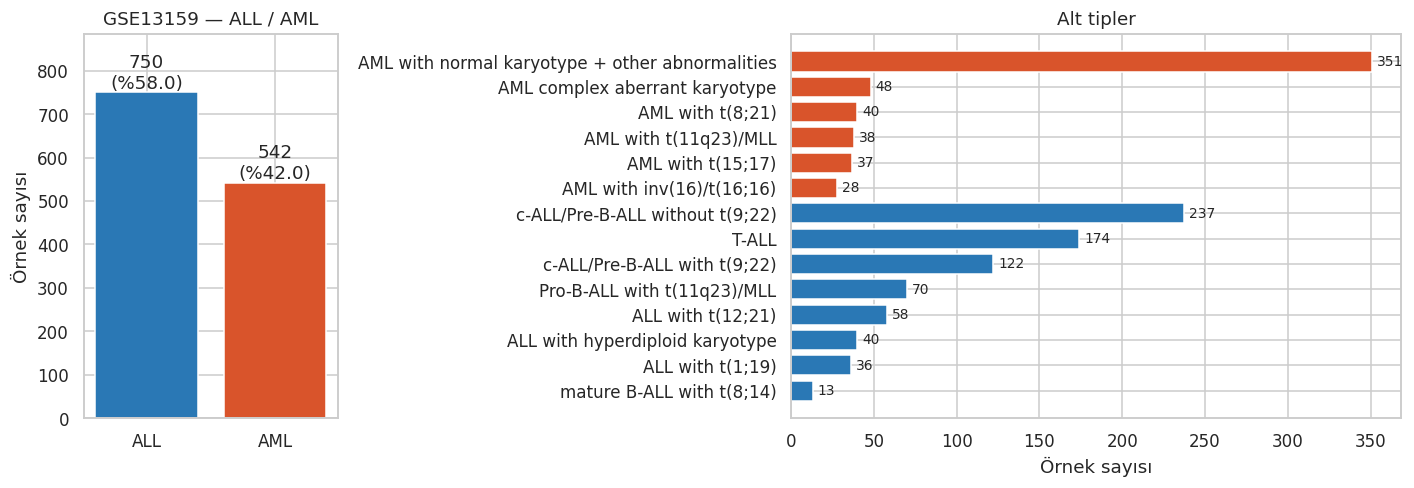

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 2.4]})
vc = pd.Series(y).value_counts().reindex(['ALL', 'AML'])
axes[0].bar(vc.index, vc.values, color=[PALETTE[k] for k in vc.index])
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f'{v}\n(%{100*v/vc.sum():.1f})', ha='center', va='bottom')
axes[0].set_title('GSE13159 — ALL / AML'); axes[0].set_ylabel('Örnek sayısı')
axes[0].set_ylim(0, vc.max() * 1.18)

sub = sel.groupby(['ALL_AML_group', 'leukemia_class']).size().reset_index(name='n')
sub = sub.sort_values(['ALL_AML_group', 'n'])
axes[1].barh(sub.leukemia_class, sub.n, color=sub.ALL_AML_group.map(PALETTE))
for i, v in enumerate(sub.n): axes[1].text(v + 3, i, str(v), va='center', fontsize=9)
axes[1].set_title('Alt tipler'); axes[1].set_xlabel('Örnek sayısı')
plt.tight_layout()
savefig('GSE13159_01_sinif_dagilimi.png')

## 6. Betimsel istatistikler

In [ ]:
per_sample = expr.describe().T
per_sample['grup'] = y
desc_by_class = per_sample.groupby('grup')[['mean', 'std', 'min', '50%', 'max']].mean()
print('Örnek başına özet istatistiklerin sınıf ortalamaları:')
display(desc_by_class.round(4))

gene_stats = pd.DataFrame({
    'ortalama': expr.mean(1), 'std': expr.std(1), 'medyan': expr.median(1),
    'min': expr.min(1), 'max': expr.max(1),
    'ALL_ort': expr.loc[:, y == 'ALL'].mean(1), 'AML_ort': expr.loc[:, y == 'AML'].mean(1)})
print('Prob bazında istatistiklerin dağılımı:')
display(gene_stats.describe().round(4))
per_sample.to_csv(os.path.join(OUT, 'GSE13159_betimsel_istatistik_ornek.csv'))
gene_stats.to_csv(os.path.join(OUT, 'GSE13159_betimsel_istatistik_prob.csv'))

Örnek başına özet istatistiklerin sınıf ortalamaları:


,mean,std,min,50%,max
grup,,,,,
ALL,0.2857,0.1981,0.0,0.2496,1.0
AML,0.2857,0.1981,0.0,0.2496,1.0


Prob bazında istatistiklerin dağılımı:


,ortalama,std,medyan,min,max,ALL_ort,AML_ort
count,54630.0000,54630.0000,54630.0000,54630.0000,54630.0000,54630.0000,54630.0000
mean,0.2857,0.0748,0.2846,0.0701,0.5470,0.2857,0.2857
std,0.1814,0.0272,0.1862,0.1369,0.1669,0.1822,0.1834
min,0.0066,0.0070,0.0000,0.0000,0.1010,0.0062,0.0063
25%,0.1383,0.0599,0.1315,0.0000,0.4045,0.1372,0.1370
50%,0.2360,0.0689,0.2404,0.0085,0.5285,0.2362,0.2343
75%,0.4053,0.0833,0.4067,0.0585,0.6857,0.4064,0.4073
max,0.9700,0.3737,0.9660,0.9130,1.0000,0.9701,0.9699


## 7. Ham ve dönüştürülmüş ifade dağılımları

GEO seri matrisindeki değerler log2 RMA ölçeğinde **değildir**. Ön kontrolde ilk 250 probta değerler 0 ile ~0,87 arasındaydı. Dönüşüm bu yüzden varsayılmaz, veriden seçilir. Havuzlanmış değerlerin çarpıklığı > 1 ise `log2(x + c)` uygulanır (c = pozitif değerlerin 1. yüzdeliği). Aksi halde ölçek korunur. Ardından görselleştirme ve PCA için prob bazında z-skoru alınır.

Ham çarpıklık: 0.697 → seçilen dönüşüm: yok (ölçek korundu) → çarpıklık: 1.128
Ham değer yüzdelikleri: {'%1': np.float64(0.0076), '%25': np.float64(0.1241), '%50': np.float64(0.2499), '%75': np.float64(0.4154), '%99': np.float64(0.8065)}
Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_02_ifade_dagilimlari_ham_donusturulmus.png


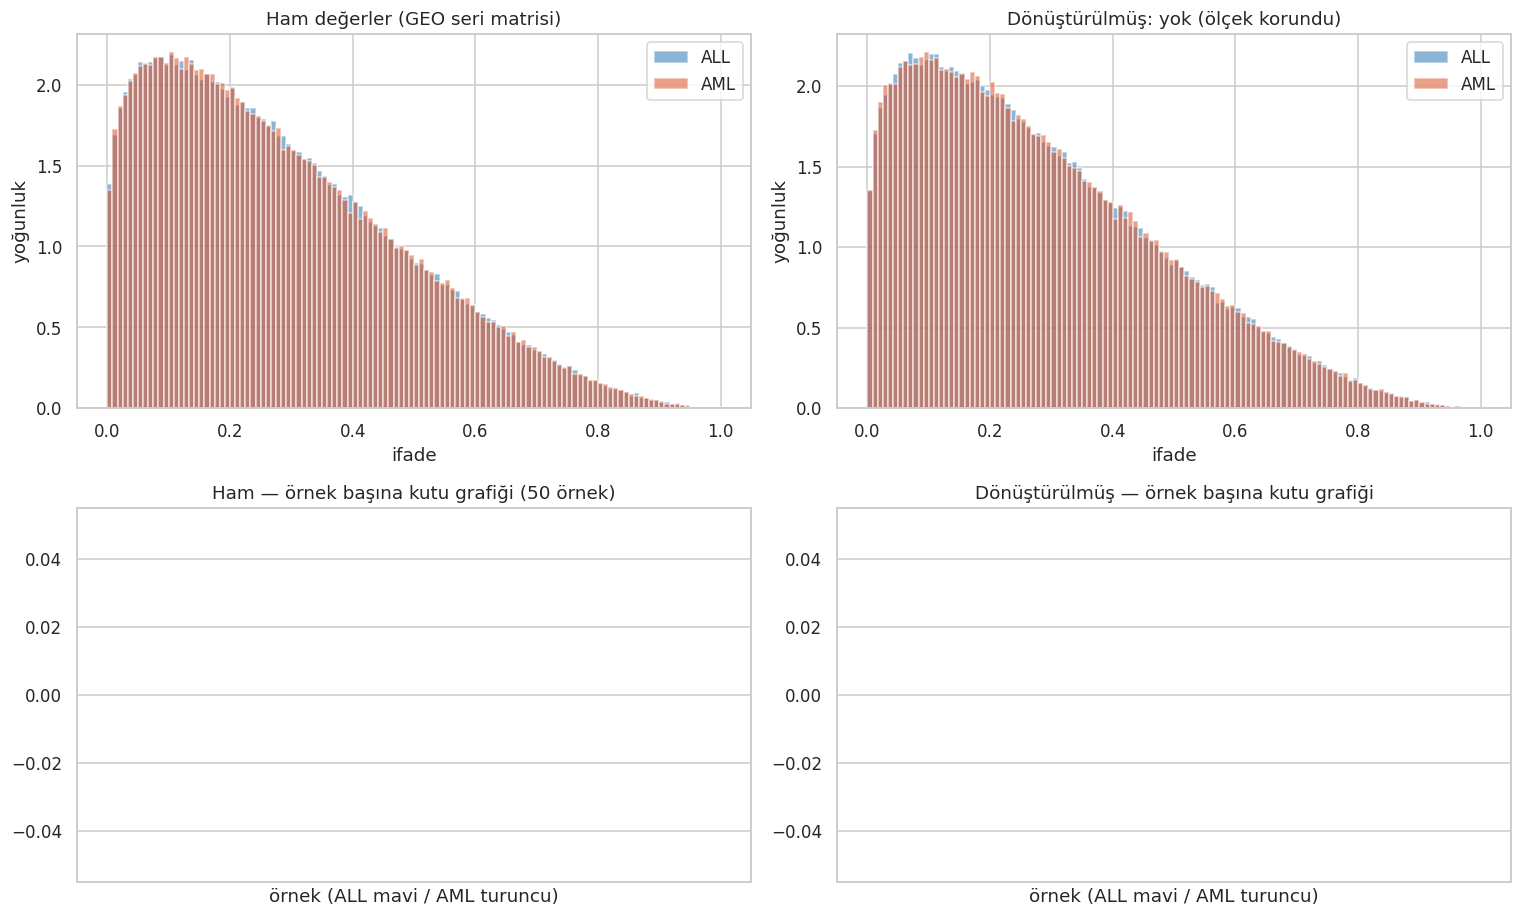

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
flat = X[~np.isnan(X)]
samp = rng.choice(flat, size=min(2_000_000, flat.size), replace=False)
skew_raw = float(stats.skew(samp))
pos = samp[samp > 0]
OFFSET = float(np.quantile(pos, 0.01)) if pos.size else 1e-3
if skew_raw > 1:
    TRANSFORM = f'log2(x + {OFFSET:.4g})'
    Xt = np.log2(X + OFFSET).astype(np.float32)
else:
    TRANSFORM = 'yok (ölçek korundu)'
    Xt = X.copy()
skew_t = float(stats.skew(Xt[~np.isnan(Xt)][:2_000_000]))
print(f'Ham çarpıklık: {skew_raw:.3f} → seçilen dönüşüm: {TRANSFORM} → çarpıklık: {skew_t:.3f}')
print('Ham değer yüzdelikleri:', dict(zip(['%1', '%25', '%50', '%75', '%99'],
      np.round(np.quantile(samp, [.01, .25, .5, .75, .99]), 4))))

mu = np.nanmean(Xt, 1, keepdims=True); sd = np.nanstd(Xt, 1, keepdims=True); sd[sd == 0] = 1
Z = (Xt - mu) / sd

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, data, ttl in [(axes[0, 0], X, 'Ham değerler (GEO seri matrisi)'),
                      (axes[0, 1], Xt, f'Dönüştürülmüş: {TRANSFORM}')]:
    for cls in ['ALL', 'AML']:
        v = data[:, y == cls].ravel()
        v = v[~np.isnan(v)]; v = rng.choice(v, min(300_000, v.size), replace=False)
        ax.hist(v, bins=120, density=True, alpha=.55, color=PALETTE[cls], label=cls)
    ax.set_title(ttl); ax.set_xlabel('ifade'); ax.set_ylabel('yoğunluk'); ax.legend()
idx = np.sort(np.concatenate([rng.choice(np.where(y == c)[0], min(25, (y == c).sum()), replace=False) for c in ['ALL', 'AML']]))
for ax, data, ttl in [(axes[1, 0], X, 'Ham — örnek başına kutu grafiği (50 örnek)'),
                      (axes[1, 1], Xt, 'Dönüştürülmüş — örnek başına kutu grafiği')]:
    bp = ax.boxplot([data[:, i] for i in idx], showfliers=False, patch_artist=True, widths=.7)
    for patch, i in zip(bp['boxes'], idx): patch.set_facecolor(PALETTE[y[i]]); patch.set_alpha(.6)
    ax.set_xticks([]); ax.set_title(ttl); ax.set_xlabel('örnek (ALL mavi / AML turuncu)')
plt.tight_layout()
savefig('GSE13159_02_ifade_dagilimlari_ham_donusturulmus.png')

## 8. PCA

Tüm örneklerde sonlu değeri olan problar arasından en değişken 5.000 prob kullanılır (geçerli prob daha azsa hepsi). Varyans etiket kullanılmadan hesaplanır.

Analize uygun prob: 54630 / 54675 (çıkarılan: 45)
Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_03_PCA.png


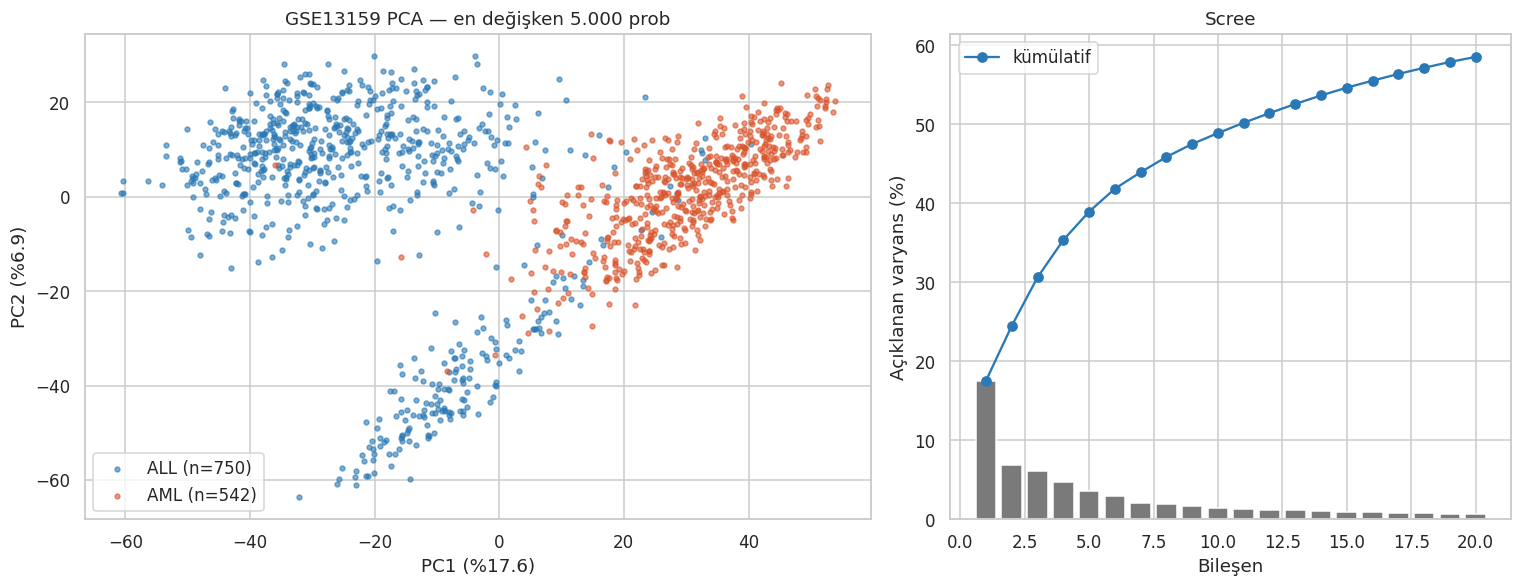

İlk 10 PC kümülatif açıklanan varyans: %48.9


In [ ]:
from sklearn.decomposition import PCA
var = np.nanvar(Xt, 1)
# v3: yalnızca tüm örneklerde sonlu değeri ve sonlu varyansı olan problar sıralanır
finite_row = np.isfinite(Xt).all(axis=1)
var_ok = np.where(finite_row & np.isfinite(var), var, -np.inf)
n_valid = int(np.isfinite(var_ok).sum())
print(f'Analize uygun prob: {n_valid} / {len(var)} (çıkarılan: {len(var) - n_valid})')
TOPN = min(5000, n_valid)
top_idx = np.argsort(var_ok)[::-1][:TOPN]
assert np.isfinite(var_ok[top_idx]).all() and np.isfinite(Z[top_idx]).all()
Zs = Z[top_idx].T                                    # örnek × prob (NaN yok)
pca = PCA(n_components=50, random_state=RANDOM_STATE).fit(Zs)
P = pca.transform(Zs)
evr = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.4, 1]})
for cls in ['ALL', 'AML']:
    m = y == cls
    axes[0].scatter(P[m, 0], P[m, 1], s=10, alpha=.6, c=PALETTE[cls], label=f'{cls} (n={m.sum()})')
axes[0].set_xlabel(f'PC1 (%{100*evr[0]:.1f})'); axes[0].set_ylabel(f'PC2 (%{100*evr[1]:.1f})')
axes[0].set_title(f"GSE13159 PCA — en değişken {f'{len(top_idx):,}'.replace(',', '.')} prob"); axes[0].legend()
axes[1].bar(range(1, 21), 100 * evr[:20], color='#7a7a7a')
axes[1].plot(range(1, 21), 100 * np.cumsum(evr[:20]), 'o-', color='#2a78b5', label='kümülatif')
axes[1].set_xlabel('Bileşen'); axes[1].set_ylabel('Açıklanan varyans (%)'); axes[1].set_title('Scree'); axes[1].legend()
plt.tight_layout()
savefig('GSE13159_03_PCA.png')
print('İlk 10 PC kümülatif açıklanan varyans: %{:.1f}'.format(100 * evr[:10].sum()))

## 9. t-SNE ve UMAP (ilk 50 PC üzerinde)

Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_04_tSNE_UMAP.png


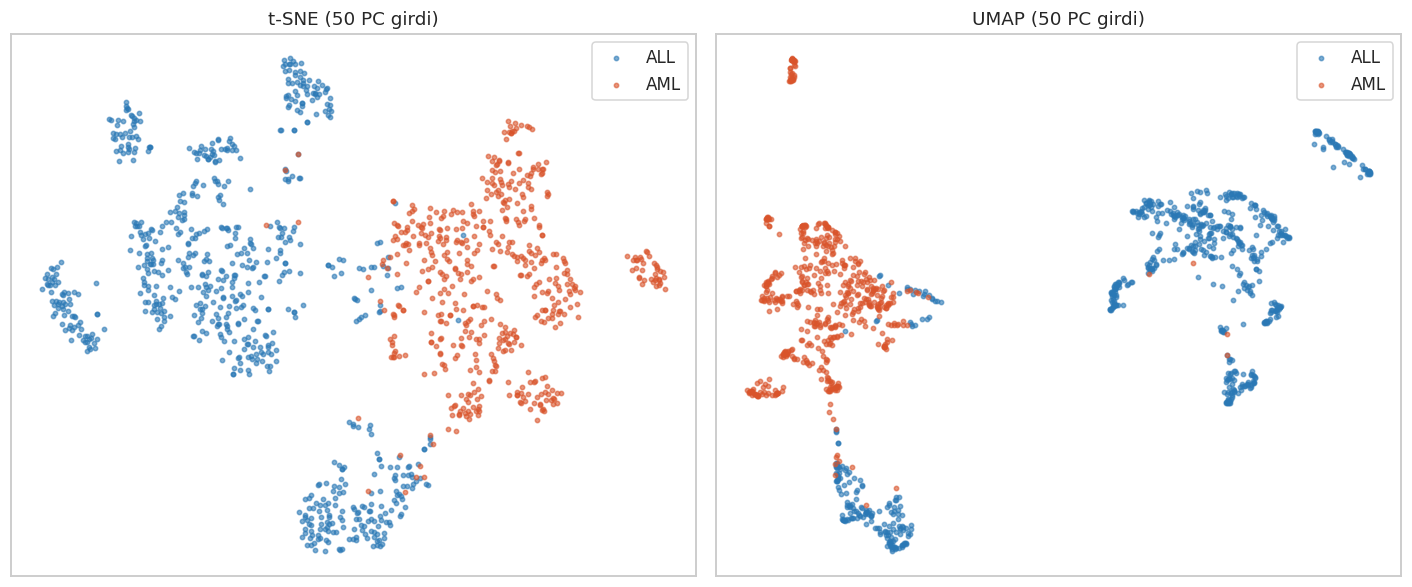

Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_05_tSNE_alt_tipler.png


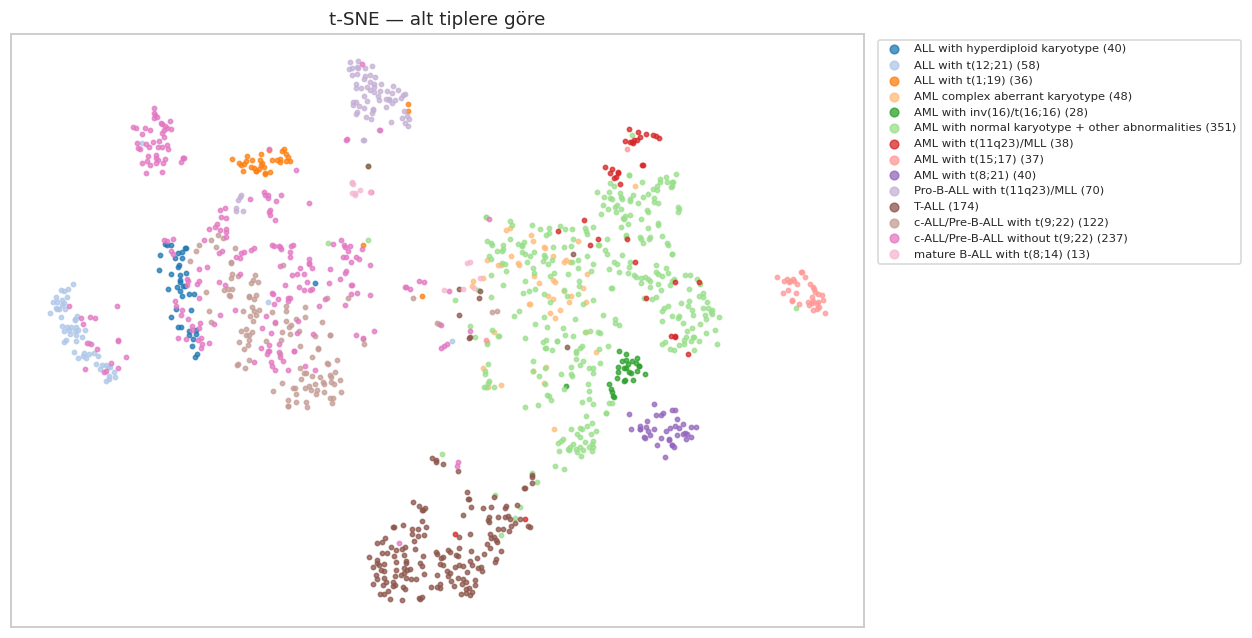

In [ ]:
from sklearn.manifold import TSNE
emb = {'t-SNE': TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(P)}
try:
    import umap
except ImportError:
    if IN_COLAB:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'umap-learn'], check=False)
    try:
        import umap
    except ImportError:
        umap = None
if umap is not None:
    emb['UMAP'] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(P)
else:
    print('UMAP kurulamadı; yalnızca t-SNE çizildi.')

fig, axes = plt.subplots(1, len(emb), figsize=(6.5 * len(emb), 5.5), squeeze=False)
for ax, (name, E) in zip(axes[0], emb.items()):
    for cls in ['ALL', 'AML']:
        m = y == cls
        ax.scatter(E[m, 0], E[m, 1], s=8, alpha=.6, c=PALETTE[cls], label=cls)
    ax.set_title(f'{name} (50 PC girdi)'); ax.set_xticks([]); ax.set_yticks([]); ax.legend()
plt.tight_layout()
savefig('GSE13159_04_tSNE_UMAP.png')

# Alt tip renklendirmesi (biyolojik yapı)
E = emb['t-SNE']
fig, ax = plt.subplots(figsize=(10, 7))
cls_list = sel.leukemia_class.values
cmap = plt.get_cmap('tab20')
for k, c in enumerate(sorted(set(cls_list))):
    m = cls_list == c
    ax.scatter(E[m, 0], E[m, 1], s=8, alpha=.75, color=cmap(k % 20), label=f'{c} ({m.sum()})')
ax.set_title('t-SNE — alt tiplere göre'); ax.set_xticks([]); ax.set_yticks([])
ax.legend(fontsize=7.5, markerscale=2, bbox_to_anchor=(1.01, 1), loc='upper left')
savefig('GSE13159_05_tSNE_alt_tipler.png')

## 10. Ayırt edici genlerin istatistiksel analizi (ALL vs AML)

Her prob için Welch t-testi ve Mann–Whitney U testi uygulanır, ardından Benjamini–Hochberg FDR düzeltmesi ve Cohen's d hesaplanır.


q(Welch, BH) < 0.05: 37741 prob   |   ayrıca |d| > 1: 2973
q(Welch, BH) < 0.01: 33752 prob   |   ayrıca |d| > 1: 2973
q(Welch, BH) < 1e-10: 17910 prob   |   ayrıca |d| > 1: 2973

En güçlü 20 prob (Welch p):


,gen_sembolu,ALL_ort,AML_ort,cohen_d,p_welch,q_welch_BH
prob_id,,,,,,
233177_s_at,PNKD,0.342865,0.589653,-3.084267,0.000000e+00,0.000000e+00
243362_s_at,LEF1-AS1,0.506754,0.157455,3.194198,0.000000e+00,0.000000e+00
210948_s_at,LEF1,0.504168,0.189332,2.849236,5.039470e-322,9.184433e-318
205382_s_at,CFD,0.338938,0.767141,-2.718799,9.653022e-301,1.319447e-296
208702_x_at,APLP2,0.514091,0.726563,-2.668312,4.731889e-298,5.174321e-294
225032_at,LOC101928615///FNDC3B,0.447015,0.666783,-2.619142,1.373063e-295,1.192935e-291
231736_x_at,MGST1,0.327081,0.709682,-3.100377,1.527306e-295,1.192935e-291
224918_x_at,MGST1,0.318494,0.724454,-2.874816,1.331380e-294,9.099153e-291
221558_s_at,LEF1,0.761189,0.391717,3.282625,6.632229e-292,4.029079e-288


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_06_volkan_ayirt_edici_genler.png


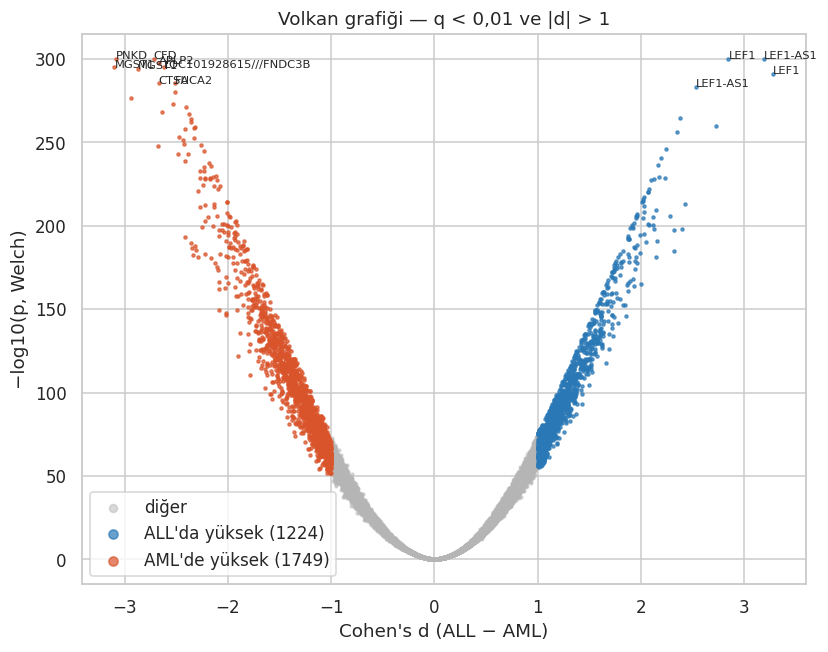

Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_07_en_ayirt_edici_8_gen_kutu.png


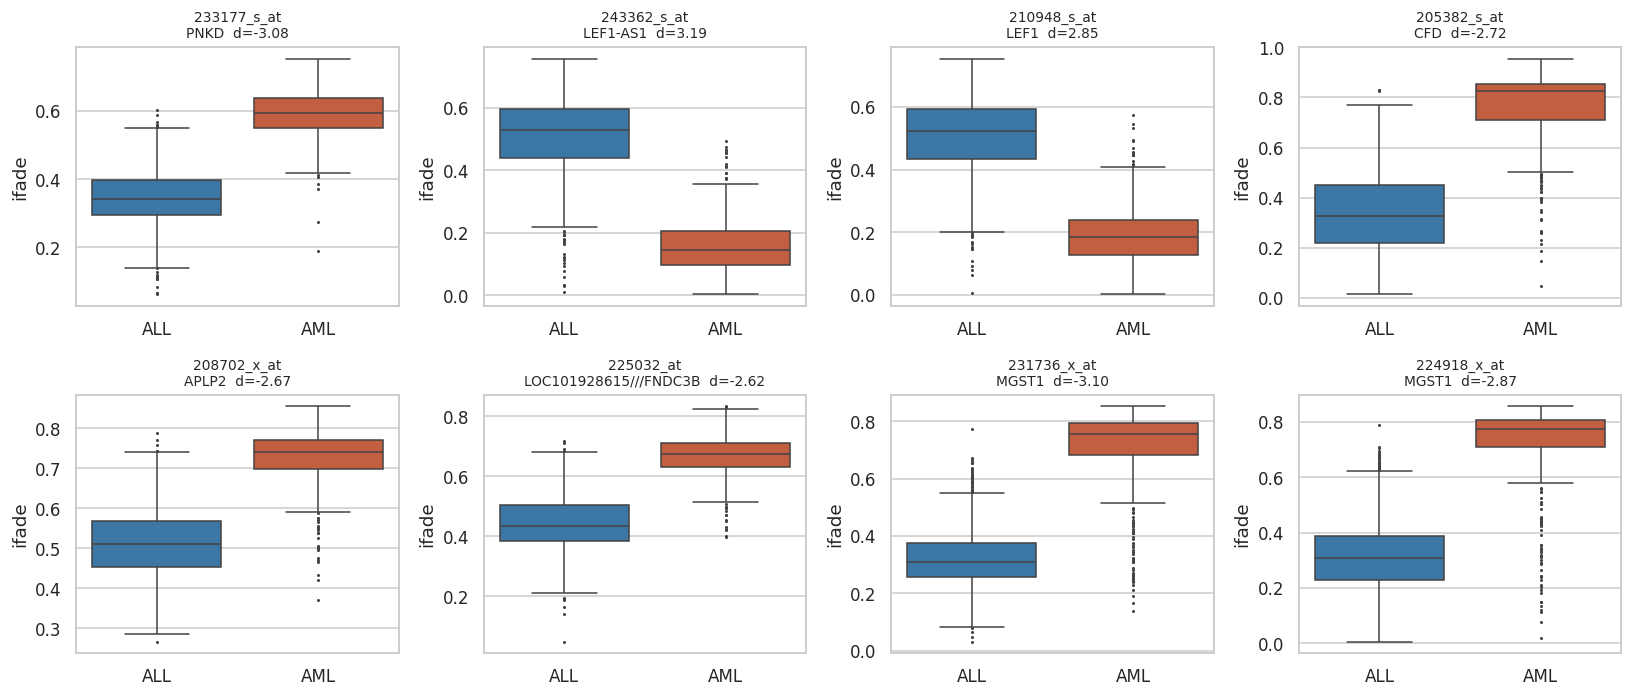

In [ ]:
def bh(p):
    p = np.asarray(p); n = p.size; o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1); return out

A, B = Xt[:, y == 'ALL'], Xt[:, y == 'AML']
t, p_t = stats.ttest_ind(A, B, axis=1, equal_var=False, nan_policy='omit')
u, p_u = stats.mannwhitneyu(A, B, axis=1, alternative='two-sided')
sp = np.sqrt(((A.shape[1]-1)*np.nanvar(A, 1, ddof=1) + (B.shape[1]-1)*np.nanvar(B, 1, ddof=1)) / (A.shape[1]+B.shape[1]-2))
d = (np.nanmean(A, 1) - np.nanmean(B, 1)) / np.where(sp == 0, np.nan, sp)

def read_annot(path):
    # GEO .annot: '^', '!', '#' ile başlayan meta satırları + '!platform_table_begin' sonrası tablo
    with gzip.open(path, 'rt', encoding='utf-8', errors='replace') as f:
        for i, line in enumerate(f):
            if line.startswith('ID\t'):
                break
    a = pd.read_csv(path, sep='\t', skiprows=i, dtype=str, compression='gzip')
    a = a[~a['ID'].astype(str).str.startswith('!')]
    return a.set_index('ID')

ann570 = read_annot(PATHS['GPL570.annot.gz'])
sym570 = ann570['Gene symbol'].reindex(expr.index)

de = pd.DataFrame({'gen_sembolu': sym570.values, 'ALL_ort': np.nanmean(A, 1), 'AML_ort': np.nanmean(B, 1),
                   'fark_ALL_eksi_AML': np.nanmean(A, 1) - np.nanmean(B, 1), 'cohen_d': d,
                   't': t, 'p_welch': p_t, 'q_welch_BH': bh(np.nan_to_num(p_t, nan=1.0)),
                   'p_mannwhitney': p_u, 'q_mannwhitney_BH': bh(np.nan_to_num(p_u, nan=1.0))},
                  index=expr.index).sort_values('p_welch')
de.index.name = 'prob_id'
de.to_csv(os.path.join(OUT, 'GSE13159_ALL_vs_AML_ayirt_edici_genler.csv'))
for thr in [0.05, 0.01, 1e-10]:
    print(f'q(Welch, BH) < {thr:g}: {(de.q_welch_BH < thr).sum()} prob   |   ayrıca |d| > 1: {((de.q_welch_BH < thr) & (de.cohen_d.abs() > 1)).sum()}')
print('\nEn güçlü 20 prob (Welch p):')
display(de.head(20)[['gen_sembolu', 'ALL_ort', 'AML_ort', 'cohen_d', 'p_welch', 'q_welch_BH']])

fig, ax = plt.subplots(figsize=(8.5, 6.5))
lp = -np.log10(np.clip(de.p_welch.values, 1e-300, 1))
sig = (de.q_welch_BH.values < 0.01) & (np.abs(de.cohen_d.values) > 1)
ax.scatter(de.cohen_d[~sig], lp[~sig], s=3, c='#b5b5b5', alpha=.5, label='diğer')
up = sig & (de.cohen_d.values > 0); dn = sig & (de.cohen_d.values < 0)
ax.scatter(de.cohen_d[up], lp[up], s=4, c=PALETTE['ALL'], alpha=.7, label=f'ALL\'da yüksek ({up.sum()})')
ax.scatter(de.cohen_d[dn], lp[dn], s=4, c=PALETTE['AML'], alpha=.7, label=f'AML\'de yüksek ({dn.sum()})')
for _, r in de.head(12).iterrows():
    ax.annotate(str(r.gen_sembolu).split(' ')[0], (r.cohen_d, -np.log10(max(r.p_welch, 1e-300))), fontsize=7.5)
ax.set_xlabel("Cohen's d (ALL − AML)"); ax.set_ylabel('−log10(p, Welch)')
ax.set_title('Volkan grafiği — q < 0,01 ve |d| > 1'); ax.legend(markerscale=3)
savefig('GSE13159_06_volkan_ayirt_edici_genler.png')

top8 = de.head(8).index
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, pid in zip(axes.ravel(), top8):
    df_ = pd.DataFrame({'ifade': Xt[expr.index.get_loc(pid)], 'grup': y})
    sns.boxplot(data=df_, x='grup', y='ifade', ax=ax, palette=PALETTE, order=['ALL', 'AML'], fliersize=1)
    ax.set_title(f"{pid}\n{str(de.loc[pid, 'gen_sembolu']).split(' ')[0]}  d={de.loc[pid, 'cohen_d']:.2f}", fontsize=9)
    ax.set_xlabel('')
plt.tight_layout()
savefig('GSE13159_07_en_ayirt_edici_8_gen_kutu.png')

## 11. En değişken 30 genin ısı haritası


Tamamen boş prob: 45 | tüm örneklerde sonlu prob: 54630 / 54675
Tamamen boş prob örnekleri: ['AFFX-BioB-3_at', 'AFFX-BioB-5_at', 'AFFX-BioB-M_at', 'AFFX-BioC-3_at', 'AFFX-BioC-5_at', 'AFFX-BioDn-3_at', 'AFFX-BioDn-5_at', 'AFFX-CreX-3_at', 'AFFX-CreX-5_at', 'AFFX-DapX-3_at']
Seçilen 30 probun varyans aralığı: 0.0666641891002655 … 0.13956739008426666
Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_08_en_degisken_30_gen_isi_haritasi.png


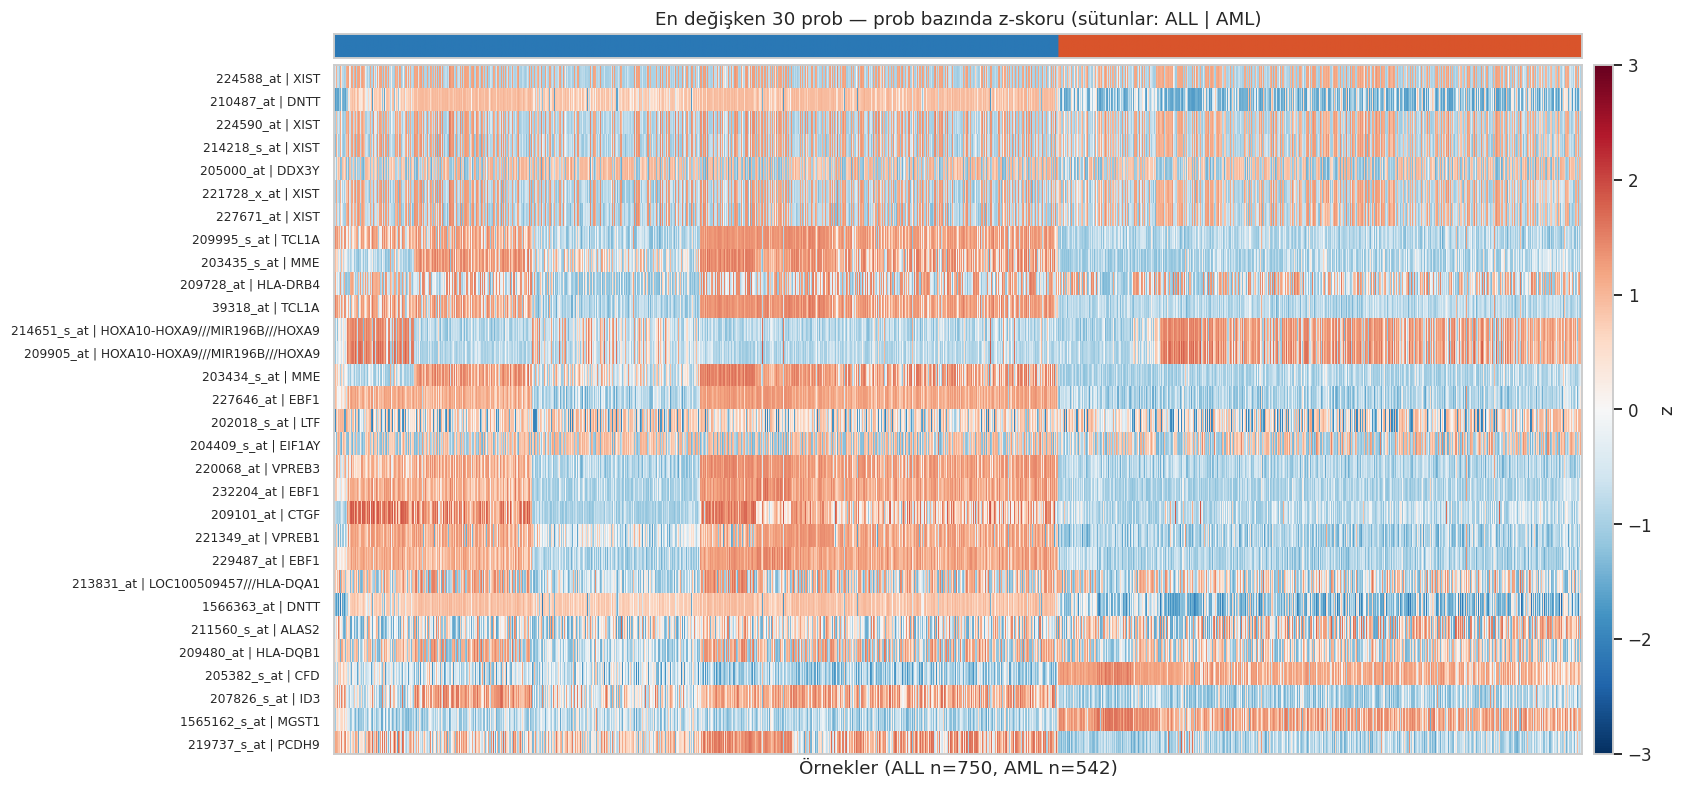

In [ ]:
# : Seri matriste 1.292 örneğin tamamında boş olan probların varyansı NaN çıkar.
# np.argsort NaN'ı sona koyar; [::-1] ters çevirince NaN'lar EN BAŞA gelir ve top30 tümüyle boş problardan oluşur.
# Bu yüzden ısı haritası için yalnızca tüm örneklerde sonlu (finite) değeri olan problar sıralanır.
all_nan = np.isnan(Xt).all(axis=1)            # finite_row ve var_ok Bölüm 8'de tanımlandı
print(f'Tamamen boş prob: {all_nan.sum()} | tüm örneklerde sonlu prob: {finite_row.sum()} / {len(finite_row)}')
print('Tamamen boş prob örnekleri:', list(expr.index[all_nan][:10]))
top30 = np.argsort(var_ok)[::-1][:30]
assert np.isfinite(var_ok[top30]).all() and np.isfinite(Z[top30]).all(), 'Seçilen 30 probda NaN/inf kaldı'
print('Seçilen 30 probun varyans aralığı:', float(var_ok[top30].min()), '…', float(var_ok[top30].max()))
H = pd.DataFrame(Z[top30], index=[f'{expr.index[i]} | {str(sym570.iloc[i]).split(" ")[0]}' for i in top30],
                 columns=expr.columns)
order = np.argsort(y, kind='stable')
H = H.iloc[:, order]
fig = plt.figure(figsize=(15, 8.5))
gs = fig.add_gridspec(2, 2, height_ratios=[0.035, 1], width_ratios=[1, 0.015], hspace=0.02, wspace=0.02)
axc = fig.add_subplot(gs[0, 0]); axh = fig.add_subplot(gs[1, 0]); axb = fig.add_subplot(gs[1, 1])
axc.imshow(np.array([[0 if v == 'ALL' else 1 for v in y[order]]]), aspect='auto',
           cmap=matplotlib.colors.ListedColormap([PALETTE['ALL'], PALETTE['AML']]))
axc.set_xticks([]); axc.set_yticks([]); axc.set_title('En değişken 30 prob — prob bazında z-skoru (sütunlar: ALL | AML)')
im = axh.imshow(np.clip(H.values, -3, 3), aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
axh.grid(False); axc.grid(False)
axh.set_yticks(range(30)); axh.set_yticklabels(H.index, fontsize=8); axh.set_xticks([])
axh.set_xlabel(f'Örnekler (ALL n={(y=="ALL").sum()}, AML n={(y=="AML").sum()})')
fig.colorbar(im, cax=axb, label='z')
savefig('GSE13159_08_en_degisken_30_gen_isi_haritasi.png')

## 12. Hiyerarşik kümeleme

Ward bağlantısı, tüm örneklerde sonlu değeri olan en değişken 1.000 probun z-skorları üzerinde uygulanır

Kümelemede kullanılan prob: 1000


,k,ARI_ALL_AML,ARI_alt_tip
0,2,0.504,0.271
1,3,0.700,0.383
2,4,0.624,0.431
3,6,0.430,0.355
4,8,0.263,0.401


küme (k=2),1,2
gerçek,,
ALL,566,184
AML,3,539


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_09_hiyerarsik_kumeleme_dendrogram.png


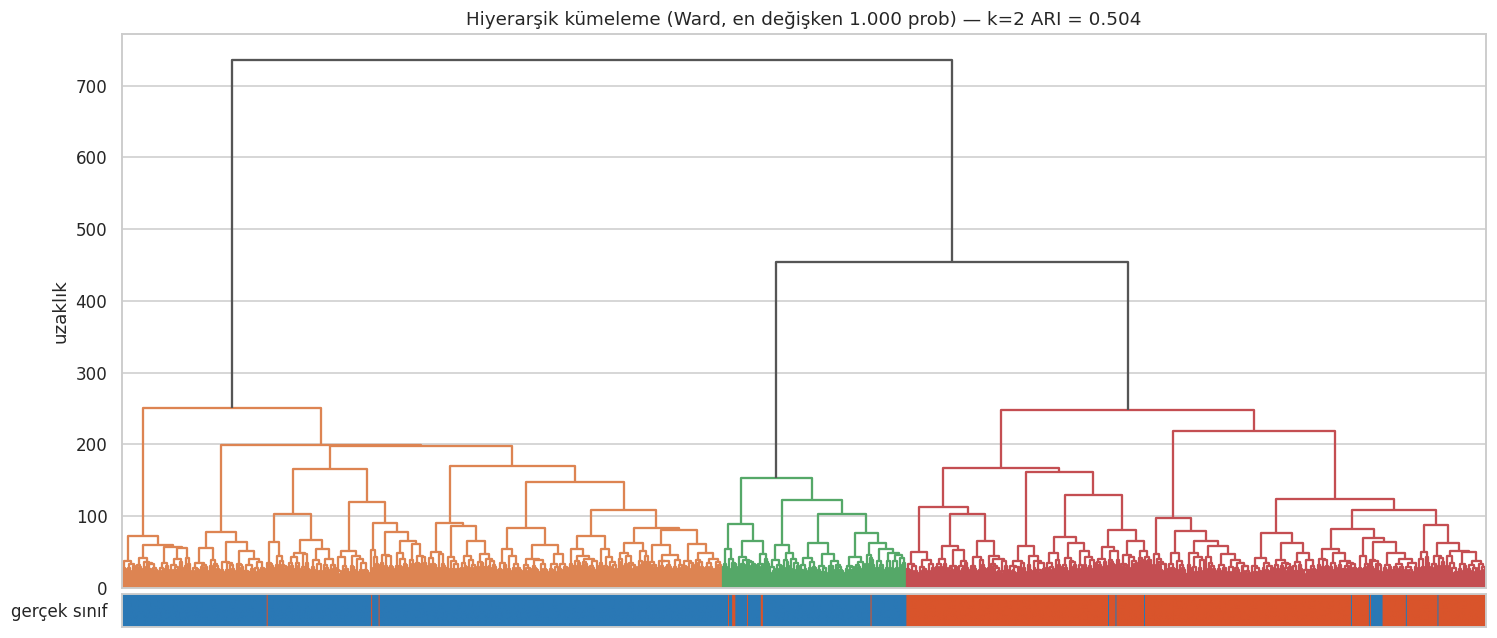

Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_10_kumeleme_isi_haritasi_30_gen.png


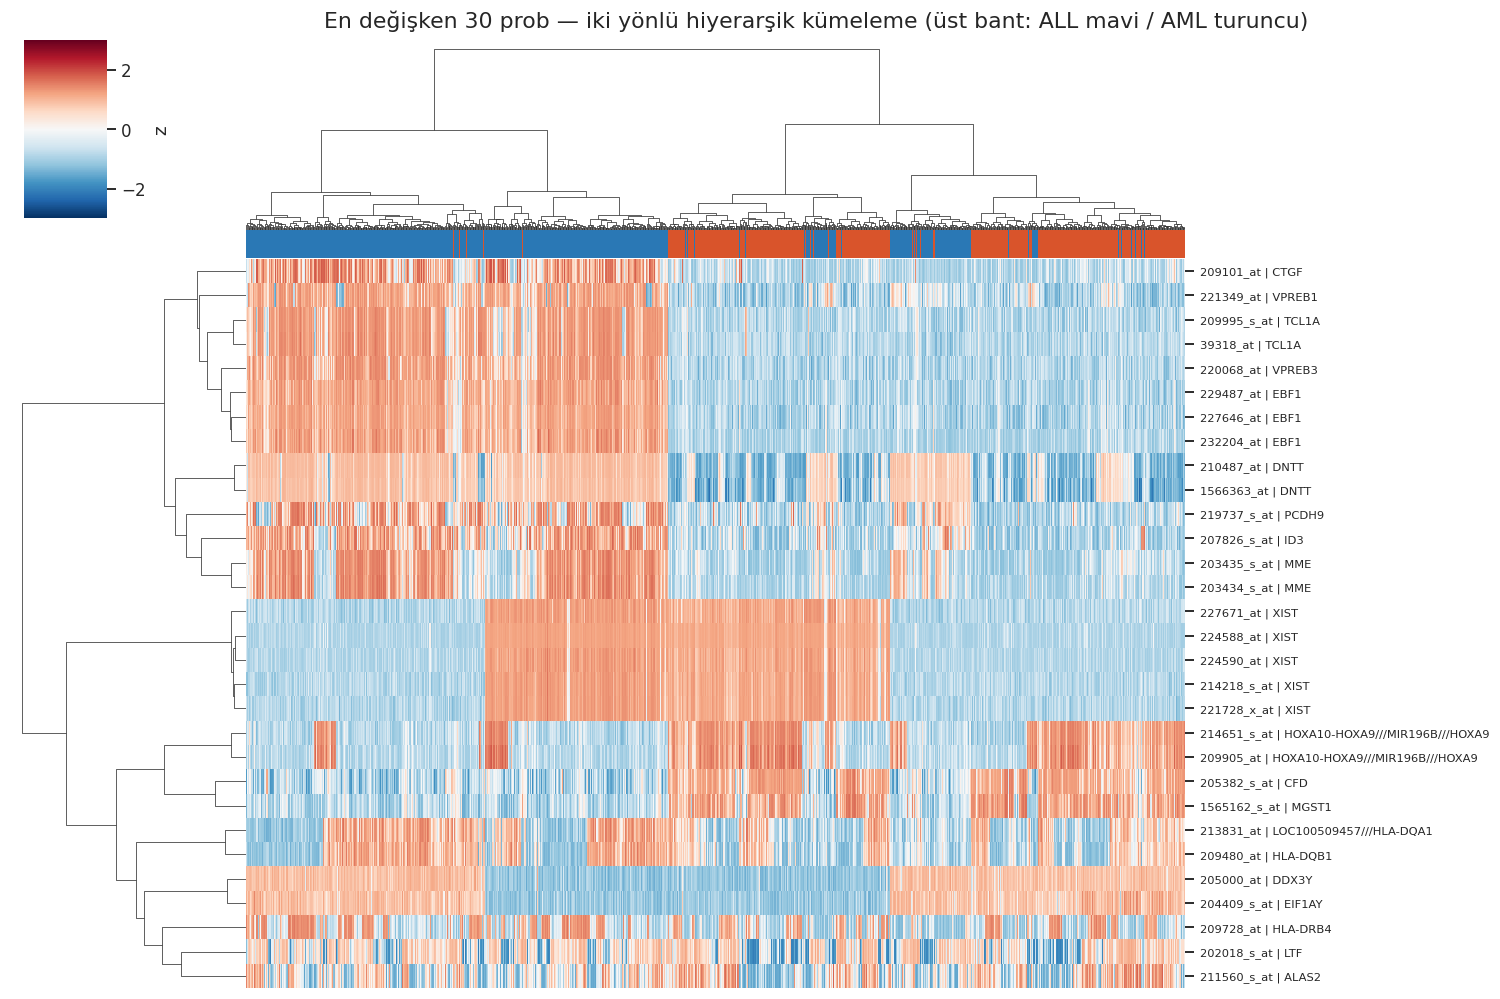

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.metrics import adjusted_rand_score
top1k = np.argsort(var_ok)[::-1][:min(1000, n_valid)]   # v3
assert np.isfinite(var_ok[top1k]).all() and np.isfinite(Z[top1k]).all()
Zc = Z[top1k].T
print('Kümelemede kullanılan prob:', len(top1k))
L = linkage(Zc, method='ward')
res = []
for k in [2, 3, 4, 6, 8]:
    cl = fcluster(L, k, criterion='maxclust')
    res.append({'k': k, 'ARI_ALL_AML': adjusted_rand_score(y, cl),
                'ARI_alt_tip': adjusted_rand_score(sel.leukemia_class, cl)})
res = pd.DataFrame(res); display(res.round(3))
cl2 = fcluster(L, 2, criterion='maxclust')
display(pd.crosstab(pd.Series(y, name='gerçek'), pd.Series(cl2, name='küme (k=2)')))
res.to_csv(os.path.join(OUT, 'GSE13159_hiyerarsik_kumeleme_ARI.csv'), index=False)

fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 0.06], hspace=0.02)
ax = fig.add_subplot(gs[0]); axc = fig.add_subplot(gs[1])
dn = dendrogram(L, ax=ax, no_labels=True, color_threshold=L[-2, 2], above_threshold_color='#555555')
ax.set_title(f"Hiyerarşik kümeleme (Ward, en değişken {f'{len(top1k):,}'.replace(',', '.')} prob) — k=2 ARI = {res.ARI_ALL_AML.iloc[0]:.3f}")
ax.set_ylabel('uzaklık')
leaves = dn['leaves']
axc.imshow(np.array([[0 if y[i] == 'ALL' else 1 for i in leaves]]), aspect='auto',
           cmap=matplotlib.colors.ListedColormap([PALETTE['ALL'], PALETTE['AML']]))
axc.grid(False); axc.set_yticks([0]); axc.set_yticklabels(['gerçek sınıf']); axc.set_xticks([])
savefig('GSE13159_09_hiyerarsik_kumeleme_dendrogram.png')

Hc = H.iloc[:, np.argsort(order)].clip(-3, 3)   # sütunlar orijinal örnek sırasına döner (col_colors = y ile hizalı)
assert np.isfinite(Hc.values).all(), 'clustermap girdisinde NaN/inf var'
g = sns.clustermap(Hc, method='ward', cmap='RdBu_r', vmin=-3, vmax=3,
                   col_colors=[PALETTE[v] for v in y], xticklabels=False, yticklabels=True,
                   figsize=(15, 9), cbar_kws={'label': 'z'})
g.ax_heatmap.tick_params(axis='y', labelsize=7.5)
g.fig.suptitle('En değişken 30 prob — iki yönlü hiyerarşik kümeleme (üst bant: ALL mavi / AML turuncu)', y=1.01)
path = os.path.join(OUT, 'GSE13159_10_kumeleme_isi_haritasi_30_gen.png')
g.savefig(path, dpi=200, bbox_inches='tight'); SAVED.append(path); print('Kaydedildi:', path); plt.show()

## 13. Golub ile karşılaştırma, bağımsızlık ve platform uyumu


In [ ]:
gfiles = {'train': 'data_set_ALL_AML_train.csv', 'independent': 'data_set_ALL_AML_independent.csv'}
golub = {k: pd.read_csv(os.path.join(GOLUB_DIR, f)) for k, f in gfiles.items()}
actual = pd.read_csv(os.path.join(GOLUB_DIR, 'actual.csv'))
actual.columns = [c.strip() for c in actual.columns]
actual['cancer'] = actual['cancer'].astype(str).str.strip()
g_tr = golub['train']
acc_col = [c for c in g_tr.columns if 'Accession' in c][0]
g_ids = g_tr[acc_col].astype(str)
val_cols = lambda df: [c for c in df.columns if re.fullmatch(r'\d+', str(c).strip())]
g_vals = np.concatenate([golub[k][val_cols(golub[k])].values.ravel().astype(float) for k in golub])
n_golub = sum(len(val_cols(golub[k])) for k in golub)
print('Golub prob sayısı:', len(g_ids), '| örnek:', n_golub, '| ALL/AML:', actual.cancer.value_counts().to_dict())
print(f'Golub değer aralığı: {g_vals.min():.0f} … {g_vals.max():.0f} | negatif oranı: %{100*(g_vals<0).mean():.1f}')

# GPL80 anotasyonu (Hu6800) — Golub prob ID'lerinin bu platforma ait olduğunu ölçerek doğrula
a80 = read_annot(PATHS['GPL80.annot.gz'])
match80 = g_ids.isin(a80.index).mean()
print(f'Golub prob ID\'lerinin GPL80 ID\'leriyle örtüşmesi: %{100*match80:.1f}')

sym80 = a80['Gene symbol'].reindex(g_ids).dropna()
def symbols(s):
    return set(x.strip() for v in s.dropna() for x in str(v).split('///') if x.strip())
sym570_ok = sym570[finite_row]                # v2: yalnızca tüm örneklerde ölçülmüş problar
S80, S570 = symbols(sym80), symbols(sym570_ok)
common = sorted(S80 & S570)
print(f'Gen sembolü — Golub: {len(S80)}, GSE13159: {len(S570)}, ORTAK: {len(common)}')

# Ortak gen eşleştirme tablosu: her gen için her platformdan prob listesi + GSE13159'da en değişken prob
probe570 = sym570_ok.dropna().str.split(' /// ').explode().str.strip()
probe80 = sym80.str.split(' /// ').explode().str.strip()
v570 = pd.Series(var_ok, index=expr.index)   # v2: tamamen boş problar -inf; seçilmez
rows = []
for gsym in common:
    p5 = probe570.index[probe570 == gsym].tolist(); p8 = probe80.index[probe80 == gsym].tolist()
    rows.append({'gen_sembolu': gsym, 'golub_problari_GPL80': ';'.join(p8), 'gse13159_problari_GPL570': ';'.join(p5),
                 'gse13159_en_degisken_prob': (v570.loc[p5].idxmax() if p5 and np.isfinite(v570.loc[p5]).any() else '')})
gmap = pd.DataFrame(rows)
gmap.to_csv(os.path.join(OUT, 'Golub_GSE13159_ortak_gen_eslestirme.csv'), index=False)
print('Kaydedildi: Golub_GSE13159_ortak_gen_eslestirme.csv', gmap.shape)

Golub prob sayısı: 7129 | örnek: 72 | ALL/AML: {'ALL': 47, 'AML': 25}
Golub değer aralığı: -28400 … 71369 | negatif oranı: %28.7
Golub prob ID'lerinin GPL80 ID'leriyle örtüşmesi: %100.0
Gen sembolü — Golub: 6071, GSE13159: 22836, ORTAK: 6005
Kaydedildi: Golub_GSE13159_ortak_gen_eslestirme.csv (6005, 4)


,Özellik,Golub (ana veri),GSE13159 (ikinci veri)
0,Kaynak / erişim,Proje klasöründeki data_set_ALL_AML_train / in...,"NCBI GEO GSE13159 (SuperSeries GSE13204), BioP..."
1,Yayın,"Golub vd., Science 1999",Kohlmann vd. 2008 BJH; Haferlach vd. 2010 JCO ...
2,Örnek sayısı (analizdeki),72 (38 eğitim + 34 bağımsız),1292 (2.096 içinden ALL+AML)
3,Sınıf dağılımı (ALL / AML),47 / 25 (%65 / %35),750 / 542 (%58 / %42)
4,Alt tip bilgisi,Yok (yalnız ALL/AML; B/T bilgisi bu dosyalarda...,8 ALL + 6 AML alt tipi (karyotip/füzyon)
5,Doku,Bu CSV dosyalarında doku bilgisi yok,Kemik iliği ve periferik kan (bkz. Bölüm 2 tab...
6,Platform,Affymetrix Hu6800 (GPL80) — prob ID örtüşmesi ...,"Affymetrix HG-U133 Plus 2.0, GPL570"
7,Prob seti sayısı,7129,54675
8,Gen sembolü (anotasyonlu),6071,22836
9,Ortak gen sembolü,6005,6005


Kaydedildi: /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159/GSE13159_11_Golub_karsilastirma_tablosu.png


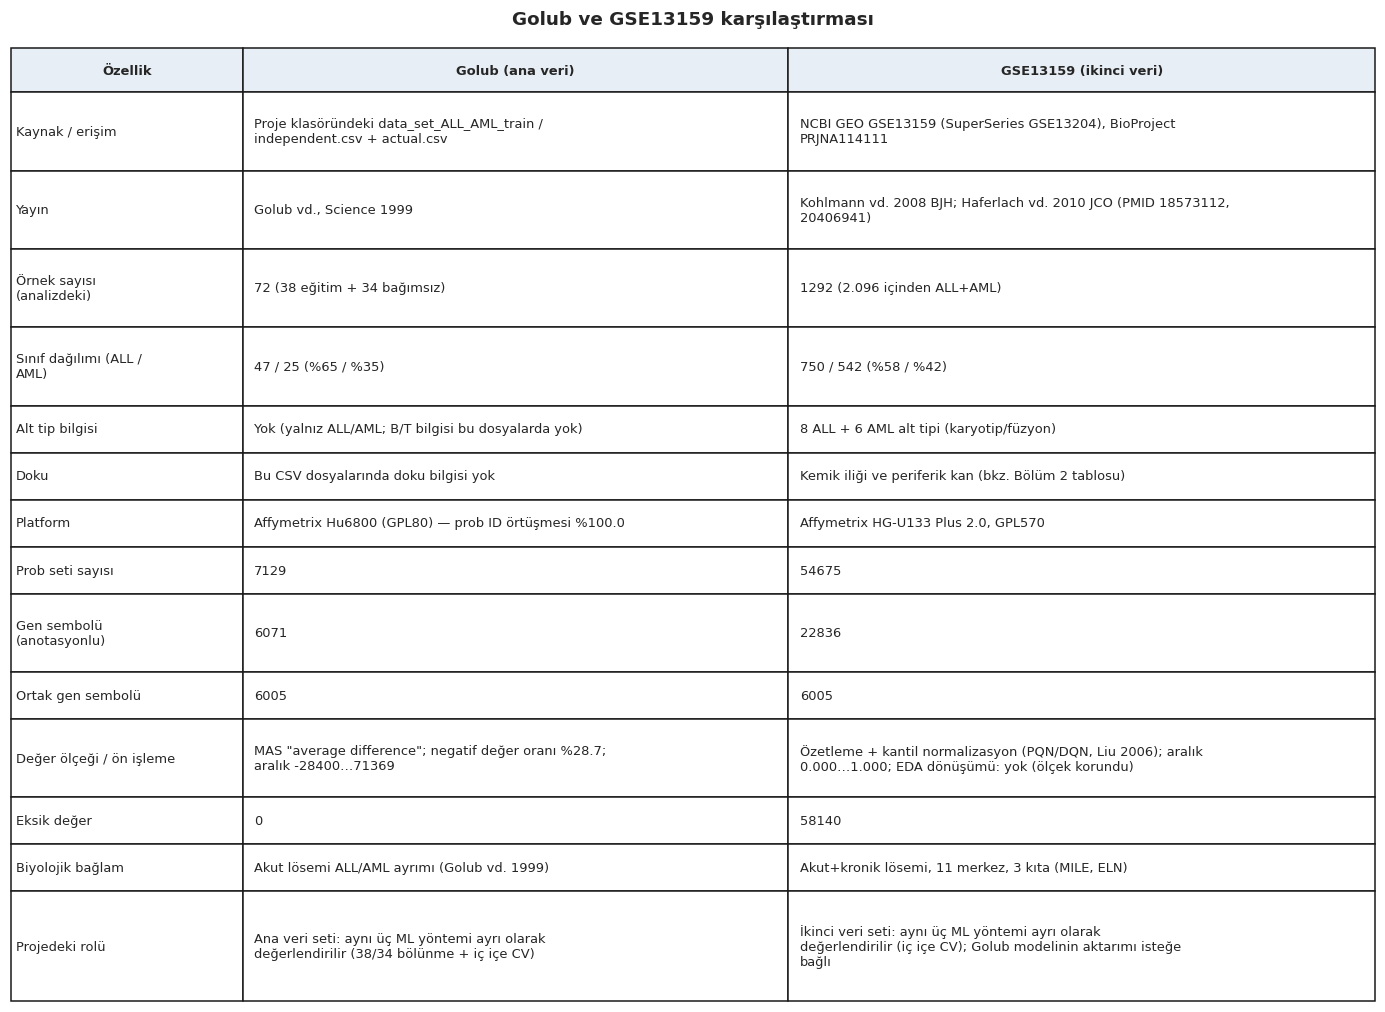

In [ ]:
nA, nM = (y == 'ALL').sum(), (y == 'AML').sum()
gA, gM = (actual.cancer == 'ALL').sum(), (actual.cancer == 'AML').sum()
comp = pd.DataFrame({
 'Özellik': ['Kaynak / erişim', 'Yayın', 'Örnek sayısı (analizdeki)', 'Sınıf dağılımı (ALL / AML)',
             'Alt tip bilgisi', 'Doku', 'Platform', 'Prob seti sayısı', 'Gen sembolü (anotasyonlu)',
             'Ortak gen sembolü', 'Değer ölçeği / ön işleme', 'Eksik değer', 'Biyolojik bağlam', 'Projedeki rolü'],
 'Golub (ana veri)': [
    'Proje klasöründeki data_set_ALL_AML_train / independent.csv + actual.csv', 'Golub vd., Science 1999',
    f'{n_golub} (38 eğitim + 34 bağımsız)', f'{gA} / {gM} (%{100*gA/(gA+gM):.0f} / %{100*gM/(gA+gM):.0f})',
    'Yok (yalnız ALL/AML; B/T bilgisi bu dosyalarda yok)', 'Bu CSV dosyalarında doku bilgisi yok',
    f'Affymetrix Hu6800 (GPL80) — prob ID örtüşmesi %{100*match80:.1f}', f'{len(g_ids)}', f'{len(S80)}', f'{len(common)}',
    f'MAS "average difference"; negatif değer oranı %{100*(g_vals<0).mean():.1f}; aralık {g_vals.min():.0f}…{g_vals.max():.0f}',
    f'{int(np.isnan(g_vals).sum())}', 'Akut lösemi ALL/AML ayrımı (Golub vd. 1999)', 'Ana veri seti: aynı üç ML yöntemi ayrı olarak değerlendirilir (38/34 bölünme + iç içe CV)'],
 'GSE13159 (ikinci veri)': [
    'NCBI GEO GSE13159 (SuperSeries GSE13204), BioProject PRJNA114111',
    'Kohlmann vd. 2008 BJH; Haferlach vd. 2010 JCO (PMID 18573112, 20406941)',
    f'{nA + nM} (2.096 içinden ALL+AML)', f'{nA} / {nM} (%{100*nA/(nA+nM):.0f} / %{100*nM/(nA+nM):.0f})',
    '8 ALL + 6 AML alt tipi (karyotip/füzyon)', 'Kemik iliği ve periferik kan (bkz. Bölüm 2 tablosu)',
    'Affymetrix HG-U133 Plus 2.0, GPL570', f'{expr.shape[0]}', f'{len(S570)}', f'{len(common)}',
    f'Özetleme + kantil normalizasyon (PQN/DQN, Liu 2006); aralık {np.nanmin(X):.3f}…{np.nanmax(X):.3f}; EDA dönüşümü: {TRANSFORM}',
    f'{n_nan}', 'Akut+kronik lösemi, 11 merkez, 3 kıta (MILE, ELN)', 'İkinci veri seti: aynı üç ML yöntemi ayrı olarak değerlendirilir (iç içe CV); Golub modelinin aktarımı isteğe bağlı'],
})
display(comp)
comp.to_csv(os.path.join(OUT, 'Golub_vs_GSE13159_karsilastirma_tablosu.csv'), index=False)

import textwrap
wrap = lambda v, w: '\n'.join(textwrap.wrap(str(v), w)) or ''
cells = [[wrap(r[0], 24), wrap(r[1], 58), wrap(r[2], 62)] for r in comp.values]
nl = [max(c.count('\n') + 1 for c in r) for r in cells]
fig, ax = plt.subplots(figsize=(16, 1.2 + 0.32 * (sum(nl) + 2))); ax.axis('off')
tb = ax.table(cellText=cells, colLabels=comp.columns, loc='upper center', cellLoc='left', colWidths=[.17, .4, .43])
tb.auto_set_font_size(False); tb.set_fontsize(8.5)
H0 = 1 / (sum(nl) + 2)
for (r, c), cell in tb.get_celld().items():
    cell.set_height(H0 * (1.4 if r == 0 else nl[r - 1] + 0.5)); cell.PAD = 0.02
    if r == 0: cell.set_facecolor('#e8eef5'); cell.set_text_props(weight='bold')
ax.set_title('Golub ve GSE13159 karşılaştırması', weight='bold')
savefig('GSE13159_11_Golub_karsilastirma_tablosu.png')

## 14. Çıktıların doğrulanması (Drive'da açılabiliyor mu?)

In [ ]:
from PIL import Image
rows = []
for f in sorted(os.listdir(OUT)):
    p = os.path.join(OUT, f); ok = None
    try:
        if f.endswith('.png'):
            with Image.open(p) as im: im.verify(); ok = 'PNG ok'
        elif f.endswith('.csv'):
            ok = f'CSV {pd.read_csv(p, nrows=5).shape[1]} sütun'
        elif f.endswith('.gz'):
            ok = 'gzip ok' if subprocess.run(['gzip', '-t', p]).returncode == 0 else 'gzip HATA'
        elif f.endswith('.parquet'):
            ok = f'parquet {pd.read_parquet(p).shape}'
        elif f.endswith('.pkl'):
            ok = f'pickle {pd.read_pickle(p).shape}'
    except Exception as e:
        ok = f'HATA: {e}'
    rows.append({'dosya': f, 'MB': round(os.path.getsize(p) / 1e6, 2), 'kontrol': ok})
check = pd.DataFrame(rows); display(check)
assert not check.kontrol.astype(str).str.startswith('HATA').any()
print(f'{len(SAVED)} grafik kaydedildi →', OUT)

,dosya,MB,kontrol
0,GPL570.annot.gz,8.47,gzip ok
1,GPL80.annot.gz,1.83,gzip ok
2,GSE13159_01_sinif_dagilimi.png,0.18,PNG ok
3,GSE13159_02_ifade_dagilimlari_ham_donusturulmu...,0.13,PNG ok
4,GSE13159_03_PCA.png,0.33,PNG ok
5,GSE13159_04_tSNE_UMAP.png,0.32,PNG ok
6,GSE13159_05_tSNE_alt_tipler.png,0.33,PNG ok
7,GSE13159_06_volkan_ayirt_edici_genler.png,0.19,PNG ok
8,GSE13159_07_en_ayirt_edici_8_gen_kutu.png,0.15,PNG ok
9,GSE13159_08_en_degisken_30_gen_isi_haritasi.png,0.39,PNG ok


11 grafik kaydedildi → /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159


In [1]:
# === GSE13159: aykırı örnek kontrolü (ara rapor, Bölüm IV-G) ===
import os, glob, json
import numpy as np, pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.covariance import MinCovDet

RANDOM_STATE = 42

# Defter baştan çalıştırılmadıysa Drive'daki işlenmiş alt kümeyi yükle
if 'Xt' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = glob.glob('/content/drive/MyDrive/**/03_Ikinci_Veri_Seti_GSE13159', recursive=True)[0]
    p_parq = os.path.join(OUT, 'GSE13159_ALL_AML_expression.parquet')
    p_pkl = os.path.join(OUT, 'GSE13159_ALL_AML_expression.pkl')
    expr = pd.read_parquet(p_parq) if os.path.exists(p_parq) else pd.read_pickle(p_pkl)
    sel = pd.read_csv(os.path.join(OUT, 'GSE13159_ALL_AML_labels.csv'))
    expr = expr[sel.geo_accession]
    y = sel.ALL_AML_group.values
    Xt = expr.values.astype(np.float32)   # GSE13159'a ek dönüşüm uygulanmıyor

# En değişken 5.000 prob (tüm örneklerde ölçülmüş problar arasından)
finite = np.isfinite(Xt).all(axis=1)
var = np.where(finite, np.nanvar(Xt, axis=1), -np.inf)
top = np.argsort(var)[::-1][:5000]
M = Xt[top]                                                          # prob × örnek
Zs = ((M - M.mean(1, keepdims=True)) / M.std(1, keepdims=True)).T   # örnek × prob

K = 10                                     # Mahalanobis için PC sayısı
esik_d2 = stats.chi2.ppf(0.999, df=K)
satirlar = []
for cls in ['ALL', 'AML']:                 # sınıf içinde: AML'nin kendisi aykırı sayılmasın
    m = (y == cls)
    # (1) Sınıf içi PCA + sağlam (MCD) Mahalanobis uzaklığı
    Pc = PCA(n_components=K, random_state=RANDOM_STATE).fit_transform(Zs[m])
    d2 = MinCovDet(random_state=RANDOM_STATE).fit(Pc).mahalanobis(Pc)
    # (2) Sınıf içindeki diğer örneklerle ortalama Pearson korelasyonu
    C = np.corrcoef(M[:, m].T)
    np.fill_diagonal(C, np.nan)
    ort_r = np.nanmean(C, axis=1)
    med = np.median(ort_r)
    mad = stats.median_abs_deviation(ort_r, scale='normal')
    esik_r = med - 3 * mad
    alt = sel.loc[m, 'leukemia_class'].values
    doku = sel.loc[m, 'sample_type'].values if 'sample_type' in sel.columns else [None] * m.sum()
    for gsm, a, b, at, dk in zip(sel.geo_accession[m], d2, ort_r, alt, doku):
        satirlar.append({'gsm': gsm, 'sinif': cls, 'alt_tip': at, 'doku': dk,
                         'mahal_d2': float(a), 'mahal_aykiri': bool(a > esik_d2),
                         'ort_r': float(b), 'r_esik': float(esik_r), 'kor_aykiri': bool(b < esik_r)})

df = pd.DataFrame(satirlar)
df['iki_olcut'] = df.mahal_aykiri & df.kor_aykiri
ozet = df.groupby('sinif')[['mahal_aykiri', 'kor_aykiri', 'iki_olcut']].sum().astype(int)
ozet['n'] = df.groupby('sinif').size()
print(ozet)
print('\nKorelasyon eşikleri:', df.groupby('sinif').r_esik.first().round(4).to_dict())
print('\nİki ölçütte de işaretlenen örnekler:')
print(df[df.iki_olcut][['gsm', 'sinif', 'alt_tip', 'doku', 'mahal_d2', 'ort_r']].round(3).to_string(index=False))

# Sonuçları Drive'a kaydet
out_dir = OUT if 'OUT' in globals() else '.'
df.to_csv(os.path.join(out_dir, 'GSE13159_aykiri_ornek_kontrolu.csv'), index=False)
json.dump({'ozet': ozet.reset_index().to_dict('records'), 'K': K, 'esik_chi2_0.999': esik_d2,
           'r_esik': df.groupby('sinif').r_esik.first().to_dict(),
           'iki_olcut_gsm': df[df.iki_olcut].gsm.tolist()},
          open(os.path.join(out_dir, 'GSE13159_aykiri_ornek_ozet.json'), 'w'), ensure_ascii=False, indent=1)
print('\nKaydedildi →', out_dir)

Mounted at /content/drive


/tmp/ipykernel_1021/1999135823.py:25: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.where(finite, np.nanvar(Xt, axis=1), -np.inf)


       mahal_aykiri  kor_aykiri  iki_olcut    n
sinif                                          
ALL             209           3          1  750
AML              49          11          3  542

Korelasyon eşikleri: {'ALL': 0.3799, 'AML': 0.4768}

İki ölçütte de işaretlenen örnekler:
      gsm sinif                                         alt_tip             doku  mahal_d2  ort_r
GSM330256   ALL                 c-ALL/Pre-B-ALL without t(9;22)      bone marrow    32.131  0.316
GSM330518   AML                           AML with t(11q23)/MLL      bone marrow    31.056  0.462
GSM330838   AML AML with normal karyotype + other abnormalities      bone marrow    41.890  0.320
GSM330843   AML AML with normal karyotype + other abnormalities peripheral blood    31.131  0.445

Kaydedildi → /content/drive/MyDrive/Donem_Projesi_Losemi/03_Ikinci_Veri_Seti_GSE13159
